Upload eth_hourly.csv


Saving eth_hourly.csv to eth_hourly.csv

🔄 Training model...

✅ RESULTS:
   R² Score: 0.9666
   RMSE: 0.032010
   Error: $151.95


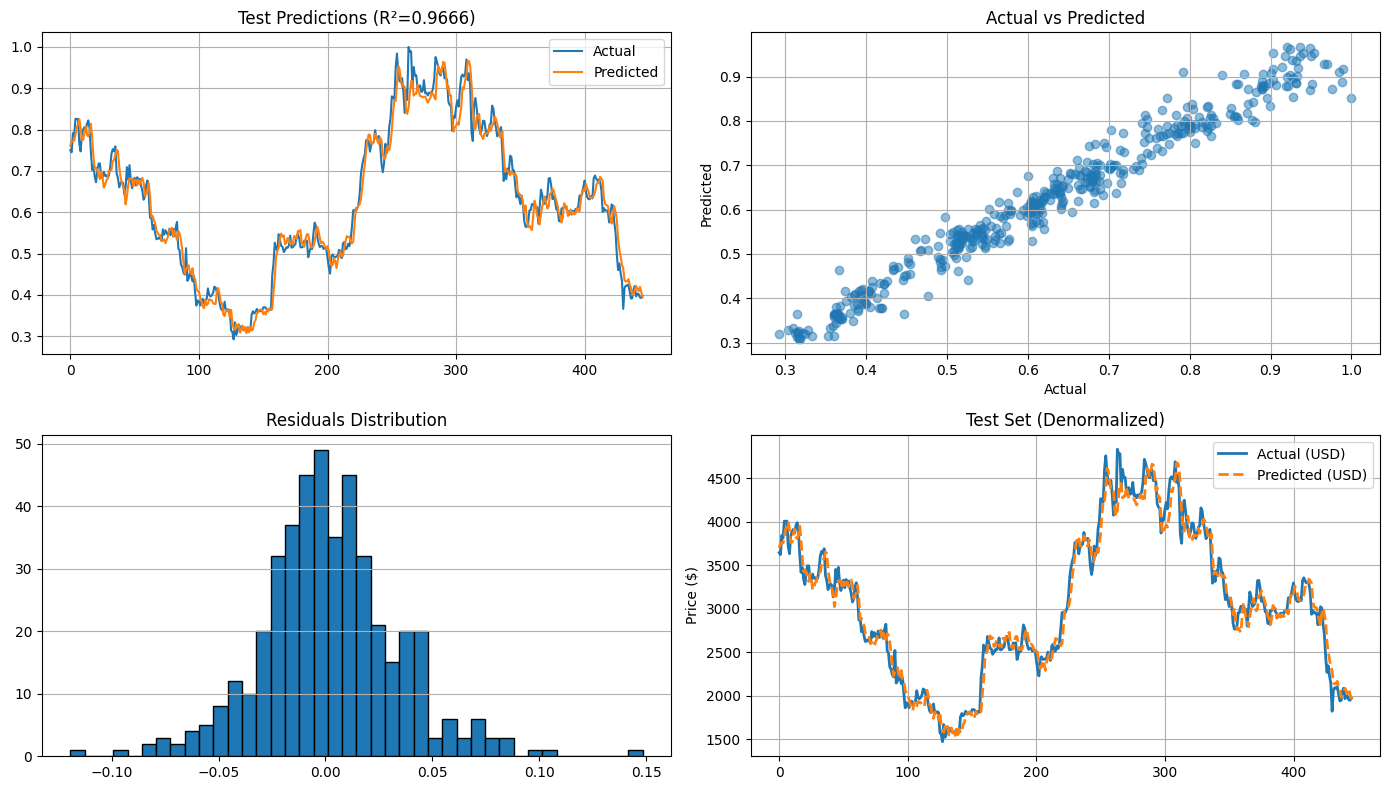


✓ Visualization saved!


In [4]:
!pip install scikit-learn pandas numpy matplotlib seaborn -q
from google.colab import files
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Upload file
print("Upload eth_hourly.csv")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Load & preprocess
df = pd.read_csv(filename)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
data = df[['close']].values

scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

def create_sequences(data, seq_length=60):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i + seq_length].flatten())
        y.append(data[i + seq_length, 0])
    return np.array(X), np.array(y)

X, y = create_sequences(scaled_data)
train_size = int(0.70 * len(X))
val_size = int(0.15 * len(X))

X_train, y_train = X[:train_size], y[:train_size]
X_val, y_val = X[train_size:train_size+val_size], y[train_size:train_size+val_size]
X_test, y_test = X[train_size+val_size:], y[train_size+val_size:]

# Train model
print("\n🔄 Training model...")
model = MLPRegressor(hidden_layer_sizes=(128, 64), solver='adam',
                     learning_rate_init=0.001, alpha=0.001,
                     max_iter=500, early_stopping=True, random_state=42)
model.fit(X_train, y_train)

# Results
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\n✅ RESULTS:")
print(f"   R² Score: {r2:.4f}")
print(f"   RMSE: {rmse:.6f}")
print(f"   Error: ${rmse * (data.max() - data.min()):.2f}")

# Visualize
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].plot(y_test, label='Actual')
axes[0, 0].plot(y_pred, label='Predicted')
axes[0, 0].set_title(f'Test Predictions (R²={r2:.4f})')
axes[0, 0].legend()
axes[0, 0].grid()

axes[0, 1].scatter(y_test, y_pred, alpha=0.5)
axes[0, 1].set_xlabel('Actual')
axes[0, 1].set_ylabel('Predicted')
axes[0, 1].set_title('Actual vs Predicted')
axes[0, 1].grid()

residuals = y_test - y_pred
axes[1, 0].hist(residuals, bins=40, edgecolor='black')
axes[1, 0].set_title('Residuals Distribution')
axes[1, 0].grid(axis='y')

# Denormalized
y_test_denorm = scaler.inverse_transform(y_test.reshape(-1, 1))
y_pred_denorm = scaler.inverse_transform(y_pred.reshape(-1, 1))
axes[1, 1].plot(y_test_denorm, label='Actual (USD)', linewidth=2)
axes[1, 1].plot(y_pred_denorm, label='Predicted (USD)', linewidth=2, linestyle='--')
axes[1, 1].set_ylabel('Price ($)')
axes[1, 1].set_title('Test Set (Denormalized)')
axes[1, 1].legend()
axes[1, 1].grid()

plt.tight_layout()
plt.savefig('eth_lstm_results.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Visualization saved!")